<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/12_%E6%A9%9F%E5%99%A8%E5%AD%B8%E7%BF%92%E8%A8%93%E7%B7%B4%E9%81%8E%E7%A8%8B/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 12. 機器學習訓練過程 (End-to-End ML Pipeline)

全書集大成實戰：工業級標準端到端流水線 (Pipeline)：
1. **載入繁體中文病理資料**。
2. **數據切分 (Train/Test Split)**。
3. **建構 Pipeline**：特徵標準化 (`StandardScaler`) + 隨機森林 (`RandomForestClassifier`)，嚴防資料洩漏。
4. **模型擬合與評估**。
5. **新數據推論預測 (Inference)**。
6. **特徵重要性視覺化**。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

# 步驟 1: 讀取繁體中文腫瘤病理資料集
df = pd.read_csv('腫瘤病理特徵資料集.csv')
features = ['腫瘤平均半徑', '腫瘤平均紋理', '腫瘤平均周長', '腫瘤平均面積', '腫瘤平滑度']
X = df[features]
y = df['診斷結果']

print("=== 步驟 1 完成：資料載入成功 ===")
print(f"樣本總數: {len(df)}，特徵數: {len(features)}")
display(df.head())


=== 步驟 1 完成：資料載入成功 ===
樣本總數: 569，特徵數: 5


,腫瘤平均半徑,腫瘤平均紋理,腫瘤平均周長,腫瘤平均面積,腫瘤平滑度,診斷結果
0,17.99,10.38,122.80,1001.0,0.11840,惡性
1,20.57,17.77,132.90,1326.0,0.08474,惡性
2,19.69,21.25,130.00,1203.0,0.10960,惡性
3,11.42,20.38,77.58,386.1,0.14250,惡性
4,20.29,14.34,135.10,1297.0,0.10030,惡性


In [4]:
# 步驟 2: 資料分割 (分層保留 20% 測試集)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"步驟 2 完成：訓練集樣本數 = {len(X_train)}，獨立測試集樣本數 = {len(X_test)}")

# 步驟 3: 建構工業級 Pipeline 流水線 (標準化 + 隨機森林)
pipeline = Pipeline([
    ('標準化縮放器', StandardScaler()),
    ('隨機森林分類器', RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42))
])

# 步驟 4: 訓練模型
pipeline.fit(X_train, y_train)
print("步驟 3 與 4 完成：Pipeline 端到端訓練完成！")


步驟 2 完成：訓練集樣本數 = 455，獨立測試集樣本數 = 114


步驟 3 與 4 完成：Pipeline 端到端訓練完成！


In [5]:
# 步驟 5: 測試集全面評估
test_acc = pipeline.score(X_test, y_test)
print(f"步驟 5 完成：測試集準確率 = {test_acc:.2%}\n")

y_pred = pipeline.predict(X_test)
print("詳細分類評估報告：")
print(classification_report(y_test, y_pred))


步驟 5 完成：測試集準確率 = 92.11%

詳細分類評估報告：
              precision    recall  f1-score   support

          惡性       0.88      0.90      0.89        42
          良性       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



=== 步驟 6: 全新病患樣本推論診斷 ===
診斷判定結果: ➔ 【惡性】
預測機率: 惡性 (99.9%), 良性 (0.1%)


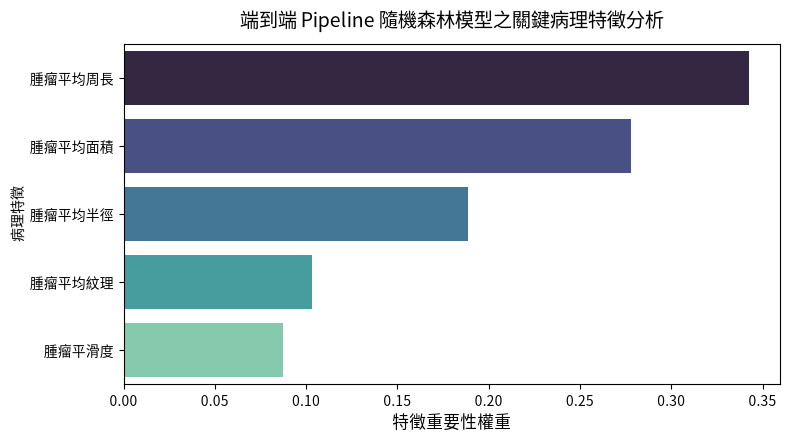


🎉 恭喜！您已成功貫通數據工程、模型優化、端到端訓練與新數據推論全流程！


In [6]:
# 步驟 6: 新數據推論與特徵重要性視覺化
# 6.1 新樣本推論預測
new_patient = X_test.iloc[:1]
prediction = pipeline.predict(new_patient)
pred_prob = pipeline.predict_proba(new_patient)
classes = pipeline.classes_

print("=== 步驟 6: 全新病患樣本推論診斷 ===")
print(f"診斷判定結果: ➔ 【{prediction[0]}】")
print(f"預測機率: {classes[0]} ({pred_prob[0][0]:.1%}), {classes[1]} ({pred_prob[0][1]:.1%})")

# 6.2 繪製特徵重要性長條圖
rf_model = pipeline.named_steps['隨機森林分類器']
feat_imp = pd.DataFrame({
    '病理特徵': features,
    '貢獻重要性': rf_model.feature_importances_
}).sort_values('貢獻重要性', ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=feat_imp, x='貢獻重要性', y='病理特徵', hue='病理特徵', palette='mako', legend=False)
plt.title('端到端 Pipeline 隨機森林模型之關鍵病理特徵分析', fontsize=14, pad=12)
plt.xlabel('特徵重要性權重', fontsize=12)
plt.tight_layout()
plt.show()

print("\n🎉 恭喜！您已成功貫通數據工程、模型優化、端到端訓練與新數據推論全流程！")
